本 notebook 是 [M02.6 数值方法](../notes/06-numerical-methods.qmd) 的实例讲解。

1. 1. 稀疏表示、LU、Cholesky 与共轭梯度
2. 2. 幂迭代与带重正交的 Lanczos
3. 3. ODE 的稳定性与守恒结构
4. 4. 插值与数值积分
5. 5. PDE 离散与网格收敛

在 VS Code 中选择仓库 `.venv` 内核，逐单元运行；运行结果随文件保存。示例使用固定随机种子和合成数据。

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib_inline.backend_inline import set_matplotlib_formats
from scipy.integrate import quad, simpson
from scipy.interpolate import PchipInterpolator
from scipy.linalg import cho_factor, cho_solve, lu_factor, lu_solve
from scipy.sparse import diags
from scipy.sparse.linalg import cg, eigsh

from semiai.plotting import AQUA, BLUE, ORANGE, use_style

use_style()
set_matplotlib_formats("svg")
rng = np.random.default_rng(42)

## 1. 稀疏表示、LU、Cholesky 与共轭梯度

构造三对角 SPD 矩阵。直接分解与迭代求解处理同一个线性系统，用残差和参考实现检查结果。

In [2]:
n = 48
A = diags([-np.ones(n - 1), 2 * np.ones(n), -np.ones(n - 1)], [-1, 0, 1], format="csr")
b = rng.normal(size=n)
x = np.zeros(n)
r = b - A @ x
p = r.copy()
rr = r @ r
for _iteration in range(2 * n):
    Ap = A @ p
    alpha = rr / (p @ Ap)
    x += alpha * p
    r -= alpha * Ap
    new_rr = r @ r
    if np.sqrt(new_rr) < 1e-10:
        break
    p = r + (new_rr / rr) * p
    rr = new_rr
reference, info = cg(A, b, rtol=1e-11, atol=0.0)
dense = A.toarray()
x_lu = lu_solve(lu_factor(dense), b)
x_chol = cho_solve(cho_factor(dense), b)
print("shape / nnz:", A.shape, A.nnz, "CG iterations:", _iteration + 1)
print("相对残差:", np.linalg.norm(b - A @ x) / np.linalg.norm(b))
print(
    "与 SciPy CG / LU / Cholesky 的差:",
    np.linalg.norm(x - reference),
    np.linalg.norm(x - x_lu),
    np.linalg.norm(x - x_chol),
)
assert info == 0 and np.allclose(x, reference, atol=1e-7)

shape / nnz: (48, 48) 142 CG iterations: 48
相对残差: 1.2861715043442575e-14
与 SciPy CG / LU / Cholesky 的差: 0.0 1.1576931613183417e-12 2.7156094897966494e-13


读法：稀疏乘法使用非零元素数而非矩阵面积决定存储与运算；CG 必须匹配 Hermitian 正定假设，并检查退出状态与残差。

## 2. 幂迭代与带重正交的 Lanczos

把大矩阵的谱问题投影到 Krylov 子空间。小例子运行到完整空间，以便和稠密本征分解独立核对。

In [3]:
n = 30
B = diags([-np.ones(n - 1), 2 * np.ones(n), -np.ones(n - 1)], [-1, 0, 1], format="csr")
q = rng.normal(size=n)
q /= np.linalg.norm(q)
for _ in range(2000):
    q = B @ q
    q /= np.linalg.norm(q)
print("幂迭代最大本征值:", q @ (B @ q))
q = rng.normal(size=n)
q /= np.linalg.norm(q)
previous = np.zeros(n)
beta = 0.0
basis = []
alphas = []
off = []
for k in range(n):
    basis.append(q.copy())
    z = B @ q - beta * previous
    alpha = q @ z
    z -= alpha * q
    Q = np.column_stack(basis)
    z -= Q @ (Q.T @ z)
    new_beta = np.linalg.norm(z)
    alphas.append(alpha)
    if k == n - 1 or new_beta < 1e-13:
        break
    off.append(new_beta)
    previous, q = q, z / new_beta
    beta = new_beta
T = np.diag(alphas) + np.diag(off, 1) + np.diag(off, -1)
ritz = np.linalg.eigvalsh(T)
exact = np.linalg.eigvalsh(B.toarray())
partial = eigsh(B, k=3, which="SA", return_eigenvectors=False, v0=rng.normal(size=n))
print("完整 Lanczos 最大谱误差:", np.max(np.abs(ritz - exact)))
print("低端 Ritz 与 SciPy eigsh:", ritz[:3], np.sort(partial))
assert np.allclose(ritz, exact, atol=1e-10)

幂迭代最大本征值: 3.98973864678379
完整 Lanczos 最大谱误差: 2.6645352591003757e-15
低端 Ritz 与 SciPy eigsh: [0.01026135 0.04094012 0.09172149] [0.01026135 0.04094012 0.09172149]


读法：Lanczos 的小三对角矩阵给出 Ritz 值；有限精度下需防止基失去正交。生产计算通常只取少量目标特征对，并报告本征残差。

## 3. ODE 的稳定性与守恒结构

比较同一谐振子的 Euler、RK4 与 velocity Verlet。这里关注长期误差结构，不只比较单步形式上的阶数。

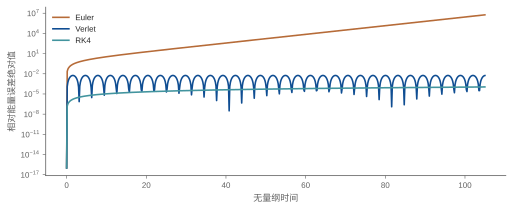

Euler 最大相对能量误差: 5811946.4057152085 末端误差: 5811946.4057152085
Verlet 最大相对能量误差: 0.005624992185326638 末端误差: -0.005508096908820592
RK4 最大相对能量误差: 0.00011042463655985824 末端误差: -0.00011042463655985824


In [4]:
def oscillator(method, h=0.15, steps=700):
    q, p = 1.0, 0.0
    energies = [0.5]
    for _ in range(steps):
        if method == "Euler":
            q, p = q + h * p, p - h * q
        elif method == "Verlet":
            p -= h * q / 2
            q += h * p
            p -= h * q / 2
        else:
            y = np.array([q, p])

            def rhs(z):
                return np.array([z[1], -z[0]])

            k1 = rhs(y)
            k2 = rhs(y + h * k1 / 2)
            k3 = rhs(y + h * k2 / 2)
            k4 = rhs(y + h * k3)
            q, p = y + h * (k1 + 2 * k2 + 2 * k3 + k4) / 6
        energies.append((q * q + p * p) / 2)
    return np.array(energies)


fig, ax = plt.subplots(figsize=(7.2, 3.0))
for method, color in [("Euler", ORANGE), ("Verlet", BLUE), ("RK4", AQUA)]:
    energy = oscillator(method)
    ax.semilogy(
        np.arange(len(energy)) * 0.15, np.abs(energy / 0.5 - 1) + 1e-16, color=color, label=method
    )
ax.set(xlabel="无量纲时间", ylabel="相对能量误差绝对值")
ax.legend()
fig.tight_layout()
plt.show()

for method in ("Euler", "Verlet", "RK4"):
    e = oscillator(method)
    print(method, "最大相对能量误差:", np.max(np.abs(e / 0.5 - 1)), "末端误差:", e[-1] / 0.5 - 1)
assert np.max(np.abs(oscillator("Verlet") / 0.5 - 1)) < 0.02

读法：显式 Euler 对纯振荡问题会持续增能；稳定区间内 Verlet 的能量误差呈有界振荡。RK4 在此时间尺度很精确，但一般不具备辛结构。

## 4. 插值与数值积分

用局部形状保持插值与积分公式处理已采样的一维数据，区分插值误差与积分误差。

In [5]:
x = np.linspace(0, np.pi, 21)
y = np.sin(x)
interp = PchipInterpolator(x, y)
probe = np.linspace(0, np.pi, 401)
print("PCHIP 最大误差:", np.max(np.abs(interp(probe) - np.sin(probe))))
print("梯形/Simpson/自适应积分:", np.trapezoid(y, x), simpson(y, x=x), quad(np.sin, 0, np.pi)[0])
assert np.allclose(interp(x), y)

PCHIP 最大误差: 0.0009097494967006403
梯形/Simpson/自适应积分: 1.9958859727087146 2.000006784441801 2.0


读法：通过已知节点不等于节点间精确；自适应积分使用被积函数重新求值，和只拥有固定样本的积分问题具有不同信息。

## 5. PDE 离散与网格收敛

对 -u''=π² sin(πx) 和零 Dirichlet 边界使用中心差分。解析解让离散化误差可以被单独测量。

In [6]:
errors = []
for n in (20, 40, 80):
    h = 1 / (n + 1)
    x = np.linspace(h, 1 - h, n)
    K = diags([-np.ones(n - 1), 2 * np.ones(n), -np.ones(n - 1)], [-1, 0, 1], format="csr") / h**2
    u, info = cg(K, np.pi**2 * np.sin(np.pi * x), rtol=1e-12, atol=0.0)
    err = np.max(np.abs(u - np.sin(np.pi * x)))
    errors.append(err)
    print("内部节点数:", n, "最大离散误差:", err, "线性求解状态:", info)
print("相邻网格误差比:", np.array(errors[:-1]) / errors[1:])
assert np.all(np.diff(errors) < 0)

内部节点数: 20 最大离散误差: 0.001861872639264739 线性求解状态: 0
内部节点数: 40 最大离散误差: 0.0004890569999245198 线性求解状态: 0
内部节点数: 80 最大离散误差: 0.00012534281945664194 线性求解状态: 0
相邻网格误差比: [3.80706674 3.90175522]


读法：网格变细后误差接近二阶缩小，线性系统求解误差已经比离散误差更小。只把求解容差设得很严格，不能代替网格收敛分析。

## 小结

数值可靠性来自问题结构、稳定实现和分层误差分析。稀疏存储节省表示成本，Krylov 方法利用矩阵作用，辛积分保留动力学结构；解析解、参考框架、残差与收敛阶共同构成验证证据。